# Implement LIME to explain individual predictions by constructing synthetic perturbed datasets, training surrogate models manually, and validating explanations through independent verification techniques.	

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Load dataset

In [6]:
df = pd.read_csv("heart.csv")

X = df.drop("HeartDisease", axis=1)
y = df["HeartDisease"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Dataset Loaded Successfully")

Dataset Loaded Successfully


# Preprocessing

In [7]:
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_cols),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

print("Preprocessing Completed!")

Preprocessing Completed!


# Train original Random Forest model

In [8]:
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train_processed, y_train)

print("Model Accuracy:", model.score(X_test_processed, y_test))

Model Accuracy: 0.9021739130434783


# Select individual prediction

In [9]:
sample_index = 0

original_patient = np.asarray(
    X_test_processed[sample_index]
).ravel()

actual_value = y_test.iloc[sample_index]

prediction = model.predict(
    original_patient.reshape(1, -1)
)[0]

probability = model.predict_proba(
    original_patient.reshape(1, -1)
)[0]

print("Actual Heart Disease:", actual_value)
print("Predicted Heart Disease:", prediction)
print("No Disease Probability:", probability[0])
print("Heart Disease Probability:", probability[1])

Actual Heart Disease: 1
Predicted Heart Disease: 1
No Disease Probability: 0.04
Heart Disease Probability: 0.96


In [10]:
np.random.seed(42)

num_samples = 1000

synthetic_data = np.random.normal(
    loc=original_patient,
    scale=0.5,
    size=(num_samples, len(original_patient))
)

print("Synthetic Dataset Shape:", synthetic_data.shape)

Synthetic Dataset Shape: (1000, 20)


In [11]:
distances = np.sqrt(
    np.sum(
        (synthetic_data - original_patient) ** 2,
        axis=1
    )
)

kernel_width = np.sqrt(len(feature_names)) * 0.75

weights = np.sqrt(
    np.exp(-(distances ** 2) / (kernel_width ** 2))
)

print("Distance Calculation Completed!")

Distance Calculation Completed!


In [12]:
synthetic_predictions = model.predict_proba(
    synthetic_data
)[:, 1]

print("Synthetic Predictions Generated!")

Synthetic Predictions Generated!


In [13]:
surrogate_model = LinearRegression()

surrogate_model.fit(
    synthetic_data,
    synthetic_predictions,
    sample_weight=weights
)

print("Surrogate Model Trained!")

Surrogate Model Trained!


In [14]:
feature_importance = np.abs(
    surrogate_model.coef_
)

lime_results = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": surrogate_model.coef_,
    "Importance": feature_importance
})

lime_results = lime_results.sort_values(
    "Importance",
    ascending=False
)

print(lime_results)

                   Feature  Coefficient  Importance
6               cat__Sex_F    -0.080081    0.080081
19        cat__ST_Slope_Up    -0.069240    0.069240
8   cat__ChestPainType_ASY     0.047899    0.047899
7               cat__Sex_M     0.043978    0.043978
4               num__MaxHR    -0.039027    0.039027
18      cat__ST_Slope_Flat     0.030711    0.030711
9   cat__ChestPainType_ATA    -0.029336    0.029336
1           num__RestingBP     0.025204    0.025204
11   cat__ChestPainType_TA    -0.020530    0.020530
10  cat__ChestPainType_NAP    -0.014125    0.014125
15   cat__ExerciseAngina_N    -0.013745    0.013745
5             num__Oldpeak     0.013069    0.013069
12     cat__RestingECG_LVH    -0.012896    0.012896
16   cat__ExerciseAngina_Y     0.012333    0.012333
2         num__Cholesterol    -0.010199    0.010199
0                 num__Age     0.006877    0.006877
17      cat__ST_Slope_Down     0.006457    0.006457
3           num__FastingBS     0.003410    0.003410
13  cat__Res

In [15]:
print("Individual Patient Explanation")
print("--------------------------------")

for _, row in lime_results.head(10).iterrows():

    direction = (
        "Increases Disease Probability"
        if row["Coefficient"] > 0
        else "Decreases Disease Probability"
    )

    print(
        row["Feature"],
        "->",
        direction,
        "-> Importance:",
        round(row["Importance"], 4)
    )

Individual Patient Explanation
--------------------------------
cat__Sex_F -> Decreases Disease Probability -> Importance: 0.0801
cat__ST_Slope_Up -> Decreases Disease Probability -> Importance: 0.0692
cat__ChestPainType_ASY -> Increases Disease Probability -> Importance: 0.0479
cat__Sex_M -> Increases Disease Probability -> Importance: 0.044
num__MaxHR -> Decreases Disease Probability -> Importance: 0.039
cat__ST_Slope_Flat -> Increases Disease Probability -> Importance: 0.0307
cat__ChestPainType_ATA -> Decreases Disease Probability -> Importance: 0.0293
num__RestingBP -> Increases Disease Probability -> Importance: 0.0252
cat__ChestPainType_TA -> Decreases Disease Probability -> Importance: 0.0205
cat__ChestPainType_NAP -> Decreases Disease Probability -> Importance: 0.0141


In [16]:
surrogate_predictions = surrogate_model.predict(
    synthetic_data
)

surrogate_r2 = r2_score(
    synthetic_predictions,
    surrogate_predictions,
    sample_weight=weights
)

surrogate_mse = mean_squared_error(
    synthetic_predictions,
    surrogate_predictions,
    sample_weight=weights
)

print("Surrogate R2 Score:", surrogate_r2)
print("Surrogate MSE:", surrogate_mse)

Surrogate R2 Score: 0.42528024887024396
Surrogate MSE: 0.0073764951857439994


In [17]:
surrogate_patient_prediction = surrogate_model.predict(
    original_patient.reshape(1, -1)
)[0]

original_patient_prediction = model.predict_proba(
    original_patient.reshape(1, -1)
)[0][1]

print("Original Model Probability:", original_patient_prediction)

print("Surrogate Model Probability:", surrogate_patient_prediction)

print(
    "Prediction Difference:",
    abs(
        original_patient_prediction -
        surrogate_patient_prediction
    )
)

Original Model Probability: 0.96
Surrogate Model Probability: 0.8384200313303194
Prediction Difference: 0.12157996866968057


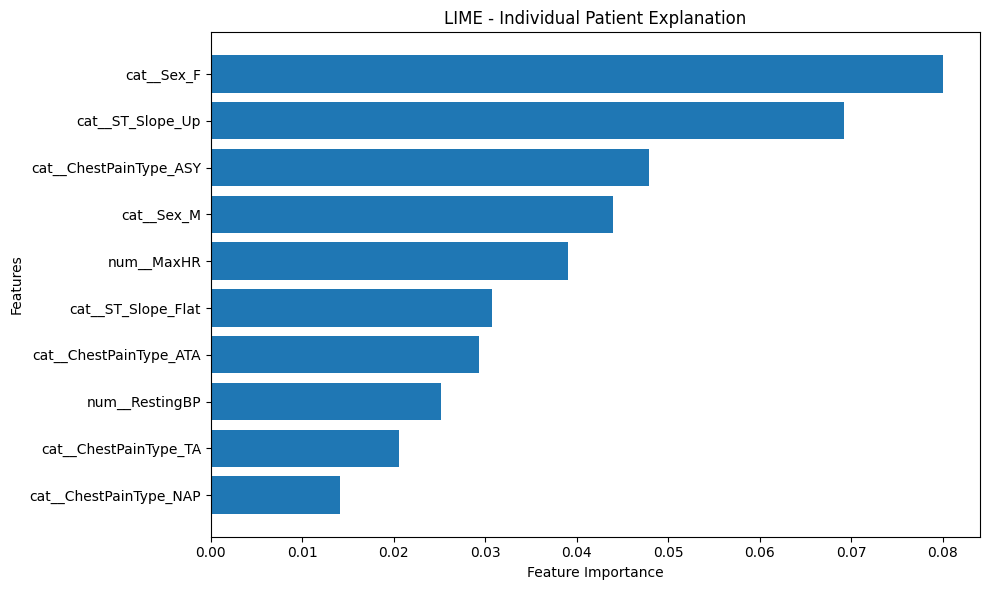

In [18]:
top_features = lime_results.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("LIME - Individual Patient Explanation")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [19]:
top_feature_index = np.argmax(feature_importance)

modified_patient = original_patient.copy()

modified_patient[top_feature_index] += 0.5

original_probability = model.predict_proba(
    original_patient.reshape(1, -1)
)[0][1]

modified_probability = model.predict_proba(
    modified_patient.reshape(1, -1)
)[0][1]

print("Feature:", feature_names[top_feature_index])

print("Original Probability:", original_probability)

print("Modified Probability:", modified_probability)

print(
    "Probability Change:",
    modified_probability - original_probability
)

Feature: cat__Sex_F
Original Probability: 0.96
Modified Probability: 0.96
Probability Change: 0.0
